In [1]:
import numpy as np
import torch.nn as nn
import torch
from torch.nn.functional import cosine_similarity
from torch.nn import CrossEntropyLoss
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
# %pip install scikit-dimension
import skdim
from skdim.id import MLE

In [2]:
k = 2
d1 = 20
d2 = 20
d = 3 # output dimension
n_train = 12000
n_test = 2000
n_expectation = 2000 # for calculating expectations of f(X), g(Y)
n = n_train + n_test

In [3]:
def generate_data(k, d1, d2, n):
      Y = np.random.randn(n, d2, 1)
      epsilon = np.random.randn(n, d1-k, 1)
      X = np.concatenate((Y[:, :k, :], epsilon), axis=1)
      return X, Y

In [4]:
def estimate_intrinsic_dimension(Z):
    """
    Z: shape (n_samples, output_dim)
    """
    Z = np.asarray(Z, dtype=np.float64)
    estimator = MLE()
    estimator.fit(Z, n_neighbors=20, comb="mle", n_jobs=-1)
    return float(estimator.dimension_)

In [5]:
X_train, Y_train = torch.tensor(generate_data(k, d1, d2, n_train), dtype=torch.float32)
X_test, Y_test = torch.tensor(generate_data(k, d1, d2, n_test), dtype=torch.float32)

In [6]:
print(X_train.shape)
print(Y_train.shape)

print(X_test.shape)
print(Y_test.shape)

torch.Size([12000, 20, 1])
torch.Size([12000, 20, 1])
torch.Size([2000, 20, 1])
torch.Size([2000, 20, 1])


In [7]:
class Encoder(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)

In [8]:
f = Encoder(input_dim=20, output_dim=3, hidden_dim=50)
g = Encoder(input_dim=20, output_dim=3, hidden_dim=50)

In [9]:
X_train_10, X_train_2, Y_train_10, Y_train_2 = train_test_split(X_train, Y_train,test_size=n_expectation, random_state=57)

In [10]:
X_train_10.shape

torch.Size([10000, 20, 1])

In [11]:
fx_10 = f(X_train_10.squeeze(dim=2))
gy_10 = g(Y_train_10.squeeze(dim=2))
fx_2 = f(X_train_2.squeeze(dim=2))
gy_2 = g(Y_train_2.squeeze(dim=2))
print(fx_10.shape, gy_10.shape)
print(fx_2.shape, gy_2.shape)

torch.Size([10000, 3]) torch.Size([10000, 3])
torch.Size([2000, 3]) torch.Size([2000, 3])


In [12]:
expected_fx = torch.norm(fx_2, dim=1).mean()
expected_gy = torch.norm(gy_2, dim=1).mean()
expected_fx, expected_gy

(tensor(0.1561, grad_fn=<MeanBackward0>),
 tensor(0.1116, grad_fn=<MeanBackward0>))

In [13]:
tau = nn.Parameter(torch.tensor(1.0))

In [14]:
# labels = torch.tensor(np.arange(f_dot_g.shape[0]))
cross_entropy_loss = CrossEntropyLoss()
# l1 = cross_entropy_loss(similarities / tau, labels)
# l2 = cross_entropy_loss(similarities.T / tau, labels)
# Loss = l1 + l2
# Loss

In [15]:
 optimizer = torch.optim.Adam(list(f.parameters()) + list(g.parameters()) + [tau], lr=0.005)
print(f.parameters)

<bound method Module.parameters of Encoder(
  (net): Sequential(
    (0): Linear(in_features=20, out_features=50, bias=True)
    (1): ReLU()
    (2): Linear(in_features=50, out_features=50, bias=True)
    (3): ReLU()
    (4): Linear(in_features=50, out_features=50, bias=True)
    (5): ReLU()
    (6): Linear(in_features=50, out_features=50, bias=True)
    (7): ReLU()
    (8): Linear(in_features=50, out_features=3, bias=True)
  )
)>


In [16]:
tau_list = []
loss_list = []
id_f_list = []
id_g_list = []
id_epochs = []
for epoch in range(600):

    optimizer.zero_grad()

    fx_10 = f(X_train_10.squeeze(dim=2))
    gy_10 = g(Y_train_10.squeeze(dim=2))
    fx_2 = f(X_train_2.squeeze(dim=2))
    gy_2 = g(Y_train_2.squeeze(dim=2))
    expected_fx = torch.norm(fx_2, dim=1).mean()
    expected_gy = torch.norm(gy_2, dim=1).mean()

    f_dot_g = fx_10 @ gy_10.T
    similarities = f_dot_g / (expected_fx * expected_gy)

    labels = torch.arange(X_train_10.shape[0])

    loss = cross_entropy_loss(similarities / tau, labels) + cross_entropy_loss(similarities.T / tau, labels)

    loss.backward()
    optimizer.step()
    tau_list.append(tau.item())
    loss_list.append(loss.item())

    if epoch % 60 == 0:
        print(epoch, loss.item(), tau.item())
    if epoch % 20 == 0:
        with torch.no_grad():
            id_f = estimate_intrinsic_dimension(fx_10.cpu().numpy())
            id_g = estimate_intrinsic_dimension(gy_10.cpu().numpy())
            id_epochs.append(epoch)
            id_f_list.append(id_f)
            id_g_list.append(id_g)

0 18.428455352783203 1.0049999952316284
60 16.232479095458984 0.6567660570144653
120 14.204459190368652 0.18646152317523956
180 15.340497970581055 0.029678406193852425
240 13.094620704650879 0.045177917927503586
300 11.440081596374512 0.05061300843954086
360 12.612286567687988 0.0859990194439888
420 8.863587379455566 0.004043801687657833
480 13.470681190490723 0.1301737278699875
540 12.787496566772461 0.11448837071657181


In [17]:
print("tau =", tau.item())
print("similarity:")
print(similarities)
print("positive:")
print(torch.diag(similarities))

mask = ~torch.eye(similarities.shape[0], dtype=torch.bool)
print("negative mean:")
print(similarities[mask].mean())

print("positive mean:")
print(torch.diag(similarities).mean())

tau = 0.0929890051484108
similarity:
tensor([[ 0.9866,  0.8826, -0.3982,  ...,  0.3905,  0.3427,  0.3392],
        [ 0.8797,  1.0448, -0.8039,  ..., -0.0582,  0.6701,  0.7333],
        [-0.3338, -0.7204,  1.0270,  ...,  0.7043, -0.4294, -0.5860],
        ...,
        [ 0.3867, -0.0828,  0.7528,  ...,  1.0053, -0.1810, -0.3434],
        [ 0.3413,  0.6316, -0.4643,  ..., -0.1170,  1.0127,  1.0199],
        [ 0.3477,  0.7115, -0.6663,  ..., -0.3078,  0.9935,  1.0418]],
       grad_fn=<DivBackward0>)
positive:
tensor([0.9866, 1.0448, 1.0270,  ..., 1.0053, 1.0127, 1.0418],
       grad_fn=<DiagonalBackward0_copy>)
negative mean:
tensor(-0.0002, grad_fn=<MeanBackward0>)
positive mean:
tensor(1.0072, grad_fn=<MeanBackward0>)


In [18]:
with torch.no_grad():
    X_test = X_test.squeeze(dim=2)
    Y_test = Y_test.squeeze(dim=2)

    fx_test = f(X_test)
    gy_test = g(Y_test)

    test_sim = (fx_test @ gy_test.T) / (expected_fx * expected_gy)

In [19]:
print("tau =", tau.item())
print("test similarity:")
print(test_sim)
positive_sim_test = torch.diag(test_sim)
print("positive:")
print(positive_sim_test)
print('positive similarities shape', positive_sim_test.shape)
mask = ~torch.eye(test_sim.shape[0], dtype=torch.bool)
negative_sim_test = test_sim[mask]
print("negative mean:")
print(negative_sim_test)
print(negative_sim_test.shape)
print("positive mean:")
print(torch.diag(test_sim).mean())

tau = 0.0929890051484108
test similarity:
tensor([[ 1.0160,  0.4433, -0.3436,  ..., -0.0400, -0.6183,  0.1971],
        [ 0.4226,  1.0072,  0.6835,  ...,  0.8407,  0.0023,  0.0110],
        [-0.3168,  0.6844,  1.0211,  ...,  0.9802,  0.2724, -0.3832],
        ...,
        [ 0.0080,  0.8063,  0.9408,  ...,  1.0092, -0.0331, -0.4601],
        [-0.6080,  0.0135,  0.2254,  ..., -0.0138,  0.9915,  0.6024],
        [ 0.1839,  0.0763, -0.4091,  ..., -0.4439,  0.5901,  1.0169]])
positive:
tensor([1.0160, 1.0072, 1.0211,  ..., 1.0092, 0.9915, 1.0169])
positive similarities shape torch.Size([2000])
negative mean:
tensor([ 0.4433, -0.3436,  0.8142,  ..., -0.2239, -0.4439,  0.5901])
torch.Size([3998000])
positive mean:
tensor(1.0041)


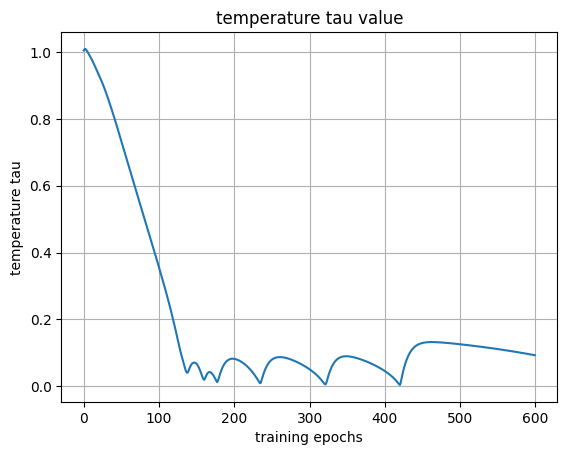

In [20]:
plt.plot(tau_list)
plt.title('temperature tau value')
plt.xlabel('training epochs')
plt.ylabel('temperature tau')
plt.grid(True)

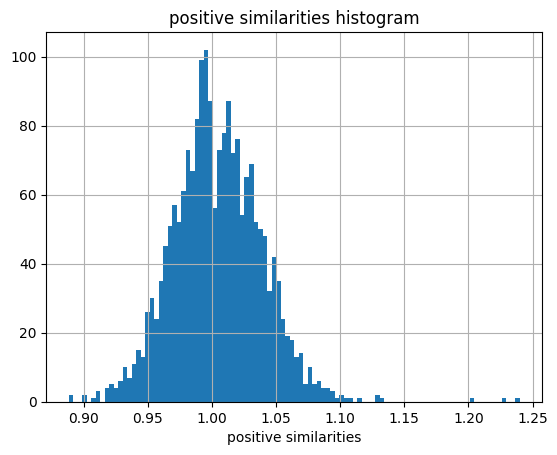

In [21]:
fig = plt.hist(positive_sim_test, bins=100)
plt.title('positive similarities histogram')
plt.xlabel('positive similarities')
plt.grid(True)
plt.show()

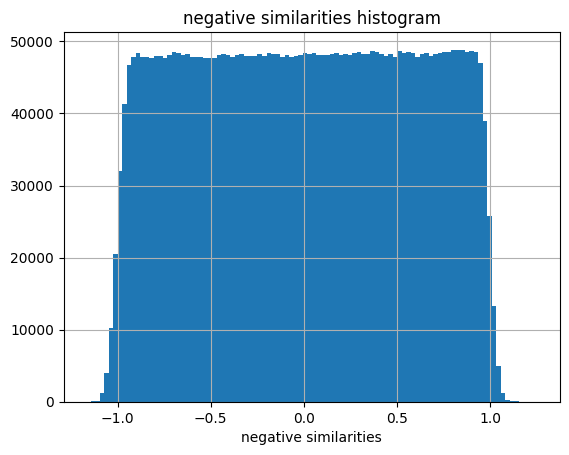

In [22]:
fig1 = plt.hist(negative_sim_test, bins=100)
plt.title('negative similarities histogram')
plt.xlabel('negative similarities')
plt.grid(True)
plt.show()

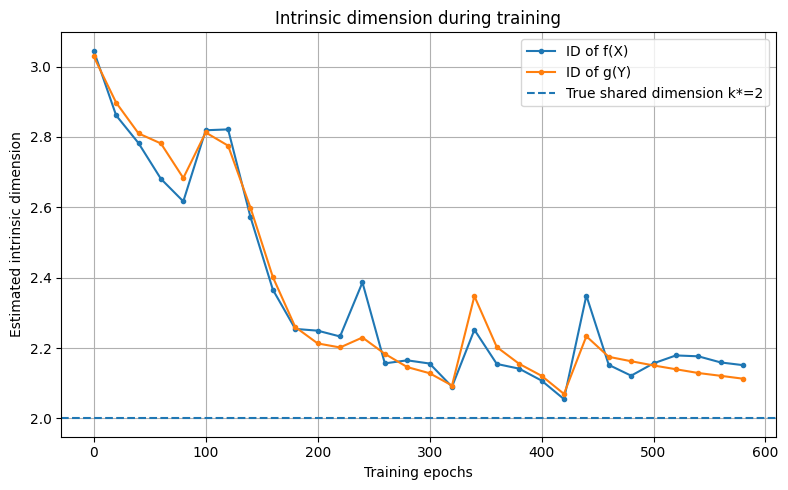

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    id_epochs,
    id_f_list,
    marker="o",
    markersize=3,
    label="ID of f(X)",
)

plt.plot(
    id_epochs,
    id_g_list,
    marker="o",
    markersize=3,
    label="ID of g(Y)",
)

plt.axhline(y=2, linestyle="--", label="True shared dimension k*=2",)

plt.xlabel("Training epochs")
plt.ylabel("Estimated intrinsic dimension")
plt.title("Intrinsic dimension during training")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()